# P1.08 — Kinds of home and kinds of price

**Questions:** RQ1.2 (prices by property type) and RQ1.8 (the gap between asking and transaction prices), each only in part.
Prices by number of rooms (T0 to T4+) are not published, so the types here are the two the data give: **new against existing
homes** (INE transaction values, 2019 onward) and **flats against villas** (bank appraisals, 2011 onward). Asking prices are
not available either; the one gap between two price measures we can build is **appraisal against transaction price**.

Appraisals are annual and suppressed for small municipalities, so trends use the same municipalities in every year; the
series with all municipalities is shown beside it because the sample grows.

In [1]:
import pandas as pd

from pthousing.analysis import price_types as pt
from pthousing.data import harmonize, interim
from pthousing.viz import charts, dashboard, style

style.apply_style()
panel = dashboard.load_panel()
valuation = interim.read("ine_bank_valuation_annual")
deflator = harmonize.annual_deflator(interim.read("ine_cpi"))

## Step 1 — New against existing homes
Premium of the price per m² of new homes over existing ones, and real price indexes (2019 = 100), for municipalities that have
both in every year 2019 to 2025. The premium by class is for 2019 and 2025, municipalities with both prices that year.

In [2]:
premium = pt.new_vs_existing(panel, 2019, 2025)
style.save_table(premium.round(2).reset_index(), "p1", "new_vs_existing")
by_class = pd.concat(
    {
        f"{by}, {year}": pt.premium_by_class(panel, year, by)
        for by in ("density_class", "coast_class")
        for year in (2019, 2025)
    },
    names=["grouping", "class"],
).round(1)
style.save_table(by_class.reset_index(), "p1", "new_premium_by_class")
print(premium.round(1).to_string())
by_class

      municipalities_n  median_premium_pct  share_new_dearer_pct  new_real_index  existing_real_index
year                                                                                                 
2019               118                24.5                  96.6           100.0                100.0
2020               118                24.2                  95.8           110.9                108.6
2021               118                25.7                  97.5           117.0                117.0
2022               118                20.7                  94.1           120.3                122.1
2023               118                19.7                  93.2           128.3                128.0
2024               118                18.8                  91.5           136.7                137.6
2025               118                12.3                  84.7           150.0                160.5


municipalities_n  median_premium_pct
grouping            class                                             
density_class, 2019 intermediate                65                23.9
                    rural                       40                28.2
                    urban                       33                23.1
density_class, 2025 intermediate                74                13.6
                    rural                       55                17.5
                    urban                       35                11.6
coast_class, 2019   coast                       61                22.5
                    estuary                      8                31.9
                    inland                      69                26.5
coast_class, 2025   coast                       64                14.5
                    estuary                      9                10.7
                    inland                      91                13.5

## Step 2 — Flats against villas
Appraised value per m², real terms. Per year the median ratio over municipalities with both types (the sample changes, so the
ratio, which is within a municipality, is the safe comparison); the change 2011 to 2025 over the municipalities with both
types in both years.

In [3]:
flats = pt.flats_vs_villas(valuation, deflator)
change = pt.valuation_change(valuation, deflator, 2011, 2025)
style.save_table(flats.round(2).reset_index(), "p1", "flats_vs_villas")
style.save_table(change.round(1).reset_index(names="type"), "p1", "flats_vs_villas_change")
print(change.round(1).to_string())
flats.round(2).T

        municipalities_n  median_real_change_pct
flats              112.0                    81.2
villas             112.0                    43.4


year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
municipalities_n,112.00,77.00,72.00,79.00,103.00,117.00,129.00,133.00,133.00,140.00,151.00,147.00,140.00,160.00,165.00
flats_real_sqm_eur,946.11,913.31,874.57,863.68,823.33,829.14,864.04,905.87,989.13,1080.83,1135.86,1177.27,1251.52,1308.50,1546.86
villas_real_sqm_eur,982.21,933.90,874.57,875.79,843.82,866.28,886.50,936.30,984.46,1023.67,1078.26,1106.77,1110.19,1184.00,1312.34
flats_to_villas,0.94,0.88,0.93,0.93,0.96,0.97,0.97,0.99,0.99,1.02,1.03,1.04,1.08,1.07,1.17


## Step 3 — Appraisal against transaction price
Appraised value over the median transaction value per m², same municipality, 2016 to 2025. The two differ in timing (appraisals
are the year's, transactions the twelve months to the fourth quarter) and in what they measure, so the level of the ratio
says little; its drift and whether appraisals lead or follow transaction prices say more.

              0     1     2    3     4
lag_years -2.00 -1.00  0.00  1.0  2.00
corr       0.06  0.05  0.32  0.1  0.08


year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
balanced_n,189.00,189.00,189.00,189.00,189.00,189.00,189.00,189.00,189.00,189.00
balanced_median,1.04,1.03,1.02,1.02,1.01,1.00,0.98,0.98,0.98,0.94
balanced_q25,0.96,0.95,0.96,0.94,0.91,0.90,0.91,0.89,0.88,0.88
balanced_q75,1.16,1.17,1.15,1.13,1.11,1.13,1.10,1.17,1.14,1.09
all_n,198.00,217.00,218.00,219.00,221.00,239.00,240.00,225.00,253.00,261.00
all_median,1.04,1.06,1.06,1.04,1.03,1.04,1.01,1.02,1.06,1.03


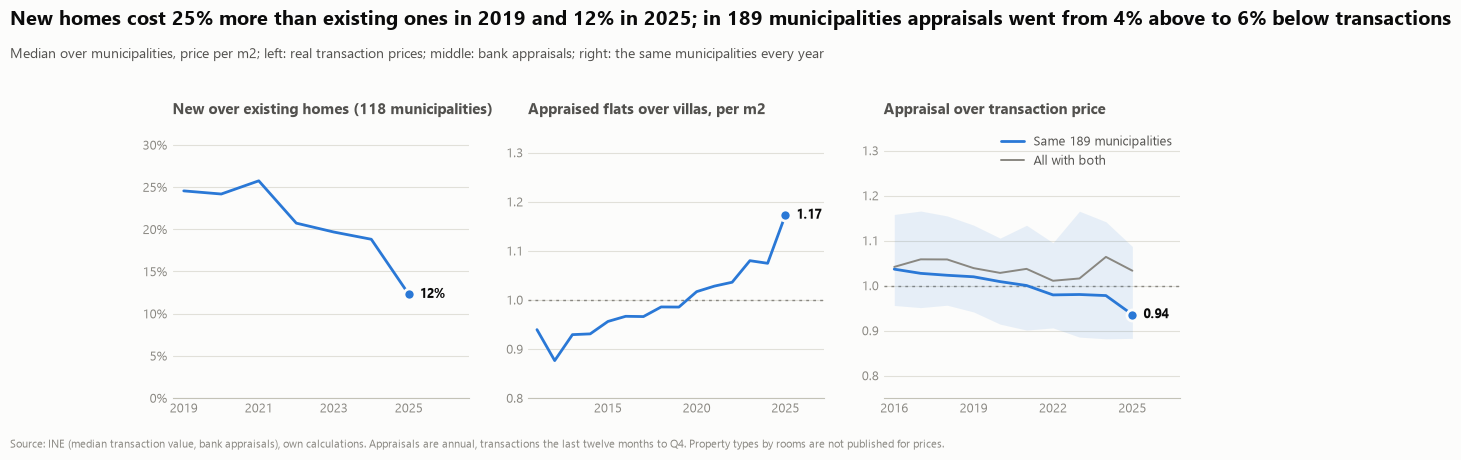

In [4]:
appraisal = pt.appraisal_vs_transaction(panel, 2016, 2025)
leadlag = pt.growth_leadlag(panel, 2016, 2025, range(-2, 3))
style.save_table(appraisal.round(3).reset_index(), "p1", "appraisal_vs_transaction")
style.save_table(leadlag.round(3), "p1", "appraisal_growth_leadlag")
fig = charts.price_kinds(premium, flats, appraisal)
style.save_fig(fig, "p1", "price_kinds")
print(leadlag.round(2).T.to_string())
appraisal.round(2).T

## Key numbers

In [5]:
p = premium
print(
    f"new-build premium {p['median_premium_pct'].iloc[0]:.1f}% (2019) to {p['median_premium_pct'].iloc[-1]:.1f}% (2025), {int(p['municipalities_n'].iloc[0])} municipalities; "
    f"new dearer in {p['share_new_dearer_pct'].iloc[0]:.0f}% then {p['share_new_dearer_pct'].iloc[-1]:.0f}%; real index 2025: new {p['new_real_index'].iloc[-1]:.0f}, existing {p['existing_real_index'].iloc[-1]:.0f}"
)
print(
    f"flats over villas {flats['flats_to_villas'].loc[2011]:.2f} (2011) to {flats['flats_to_villas'].iloc[-1]:.2f} ({flats.index[-1]}); "
    f"real change 2011-2025: flats {change.loc['flats', 'median_real_change_pct']:+.0f}%, villas {change.loc['villas', 'median_real_change_pct']:+.0f}% ({int(change['municipalities_n'].iloc[0])} municipalities)"
)
a = appraisal
print(
    f"appraisal over transaction: balanced {a['balanced_median'].iloc[0]:.2f} (2016) to {a['balanced_median'].iloc[-1]:.2f} (2025), n {int(a['balanced_n'].iloc[0])}; "
    f"all with both {a['all_median'].iloc[0]:.2f} to {a['all_median'].iloc[-1]:.2f} (n {int(a['all_n'].iloc[0])} to {int(a['all_n'].iloc[-1])})"
)

new-build premium 24.5% (2019) to 12.3% (2025), 118 municipalities; new dearer in 97% then 85%; real index 2025: new 150, existing 160
flats over villas 0.94 (2011) to 1.17 (2025); real change 2011-2025: flats +81%, villas +43% (112 municipalities)
appraisal over transaction: balanced 1.04 (2016) to 0.94 (2025), n 189; all with both 1.04 to 1.03 (n 198 to 261)
